# Detector comparison: baseline vs. YOLOv10-S + P2 vs. Faster R-CNN

Compares all detector outputs using the baseline scoring functions. Run once on the test set after detections are available.

## 1. CONFIG

In [11]:
import sys, io, json, contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from PIL import Image
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

OUT_ROOT = Path('/content/drive/MyDrive/DATA255/outputs') if IN_COLAB else ROOT / 'outputs'
DATA_CANDIDATES = [ROOT / 'data' / 'processed', Path('/content/processed'), Path('/content/drive/MyDrive/DATA255')]

# same constants as the baseline notebook
EVAL_CONF = 0.001
COUNT_CONF = 0.25
IOU_MATCH = 0.5
SEED = 0
COCO_TO_OURS = {2: 0, 5: 1, 7: 3}
IMGSZ, BATCH, DEVICE = 640, 16, None   # only used by predict_detections, which is not called here

BOOTSTRAP = 2000   # resamples of test videos for the error bars

## 2. SETUP

For Colab: mount Google Drive and copy the P2 model and processed dataset files, skipped if local

In [12]:
if IN_COLAB:
    import subprocess
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pycocotools'], check=True)
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load the detector CSV files and test dataset.

In [13]:
BASELINE_DIR, P2_DIR, FRCNN_DIR = OUT_ROOT / 'yolov10_baseline', OUT_ROOT / 'yolov10_p2', OUT_ROOT / 'faster_rcnn'
OUTPUT_DIR = OUT_ROOT / 'comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALL_SYSTEMS = {'baseline': BASELINE_DIR / 'yolo_detections_test.csv',
               'p2': P2_DIR / 'p2_detections_test.csv',
               'frcnn': FRCNN_DIR / 'frcnn_detections_test.csv'}
SYSTEMS = {k: p for k, p in ALL_SYSTEMS.items() if p.exists()}
for k, p in ALL_SYSTEMS.items():
    print(f'{k:9s}', 'OK     ' if p.exists() else 'MISSING', p)
assert 'baseline' in SYSTEMS, 'baseline detections are required (Person 2 Drive folder)'

# (file, model name inside the file); first existing file wins
SPEED_FILES = {'baseline': [(P2_DIR / 'speed_fps.csv', 'yolov10s_baseline'), (BASELINE_DIR / 'speed_fps.csv', None)],
               'p2': [(P2_DIR / 'speed_fps.csv', 'yolov10s_p2')],
               'frcnn': [(FRCNN_DIR / 'frcnn_speed.csv', None)]}

DATA_DIR = next(d for d in DATA_CANDIDATES if (d / 'frame_manifest.csv').exists())
with open(next(d / 'data.yaml' for d in DATA_CANDIDATES if (d / 'data.yaml').exists())) as f:
    names = yaml.safe_load(f)['names']
CLASS_NAMES = list(names) if isinstance(names, list) else [names[i] for i in sorted(names)]
NUM_CLASSES = len(CLASS_NAMES)

manifest = pd.read_csv(DATA_DIR / 'frame_manifest.csv')
manifest['image'] = manifest['image_path'].map(lambda p: Path(p).stem)
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
WEATHERS = sorted(test_df['weather'].unique())

gt_file = pd.read_csv(BASELINE_DIR / 'ground_truth_test.csv')
assert set(gt_file['image']) <= set(test_df['image']), 'ground truth and manifest do not match (different split?)'
print(f'{len(gt_file)} ground-truth boxes, {len(test_df)} test images, classes {CLASS_NAMES}')

baseline  OK      /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/yolo_detections_test.csv
p2        OK      /content/drive/MyDrive/DATA255/outputs/yolov10_p2/p2_detections_test.csv
frcnn     OK      /content/drive/MyDrive/DATA255/outputs/faster_rcnn/frcnn_detections_test.csv
13221 ground-truth boxes, 2489 test images, classes ['car', 'bus', 'van', 'others']


Use the shared scoring helpers from the baseline.

In [14]:
BOX_COLS = ['x1', 'y1', 'x2', 'y2']


def load_ground_truth(images_df):
    # Reads the YOLO label files and return one row per box in pixel coordinates.
    rows = []
    for r in images_df.itertuples():
        width, height = Image.open(r.image_file).size
        for line in Path(r.label_file).read_text().splitlines():
            if not line.strip():
                continue
            class_id, xc, yc, w, h = line.split()
            xc, w = float(xc) * width, float(w) * width
            yc, h = float(yc) * height, float(h) * height
            rows.append({'image': r.image, 'class_id': int(class_id),
                         'x1': xc - w / 2, 'y1': yc - h / 2, 'x2': xc + w / 2, 'y2': yc + h / 2})
    return pd.DataFrame(rows, columns=['image', 'class_id'] + BOX_COLS)


def predict_detections(model, images_df, conf, class_map=None):
    # Predicts boxes for the given images and returns one row per box in pixel coordinates.
    rows = []
    paths = images_df['image_file'].tolist()
    for start in range(0, len(paths), BATCH):
        results = model.predict(paths[start:start + BATCH], conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)
        for result in results:
            image = Path(result.path).stem
            boxes = result.boxes
            for box, cls, score in zip(boxes.xyxy.tolist(), boxes.cls.int().tolist(), boxes.conf.tolist()):
                if class_map is not None:
                    if cls not in class_map:
                        continue
                    cls = class_map[cls]
                rows.append({'image': image, 'class_id': cls, 'confidence': score,
                             'x1': box[0], 'y1': box[1], 'x2': box[2], 'y2': box[3]})
        del results
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return pd.DataFrame(rows, columns=['image', 'class_id', 'confidence'] + BOX_COLS)


def coco_ap(gt, det, image_names, agnostic=False):
    # AP with pycocotools. Returns {name: (AP50, AP50_95)} per class plus 'all' (mean over classes).
    # Classes with no ground truth in these images get NaN. agnostic=True -> one 'vehicle' class.
    image_ids = {name: i + 1 for i, name in enumerate(image_names)}
    gt = gt[gt['image'].isin(image_ids)]
    det = det[det['image'].isin(image_ids)]
    cat_names = ['vehicle'] if agnostic else CLASS_NAMES
    to_cat = (lambda c: 1) if agnostic else (lambda c: int(c) + 1)   # COCO category IDs start at 1

    coco_gt = COCO()
    coco_gt.dataset = {
        'images': [{'id': i} for i in image_ids.values()],
        'categories': [{'id': k + 1, 'name': n} for k, n in enumerate(cat_names)],
        'annotations': [{'id': k + 1, 'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1],
                         'area': (r.x2 - r.x1) * (r.y2 - r.y1), 'iscrowd': 0}
                        for k, r in enumerate(gt.itertuples())],
    }
    has_gt = {n: (gt['class_id'] == k).any() if not agnostic else len(gt) > 0 for k, n in enumerate(cat_names)}

    if len(det) == 0:   # no detections at all: AP is 0 wherever there is ground truth
        out = {n: (0.0, 0.0) if has_gt[n] else (np.nan, np.nan) for n in cat_names}
    else:
        with contextlib.redirect_stdout(io.StringIO()):   # hide pycocotools' printouts
            coco_gt.createIndex()
            coco_det = coco_gt.loadRes([{'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1], 'score': r.confidence}
                                        for r in det.itertuples()])
            ev = COCOeval(coco_gt, coco_det, 'bbox')
            ev.params.maxDets = [1, 10, 300]   # allow up to 300 boxes per image (busy traffic scenes)
            ev.evaluate()
            ev.accumulate()
        # precision has shape [IoU thresholds (0.5..0.95), recall points, class, area range, maxDets]
        precision = ev.eval['precision'][:, :, :, 0, -1]
        out = {}
        for k, n in enumerate(cat_names):
            p = precision[:, :, k]
            out[n] = (p[0][p[0] > -1].mean(), p[p > -1].mean()) if has_gt[n] else (np.nan, np.nan)

    out['all'] = tuple(np.nanmean([out[n][j] for n in cat_names]) for j in (0, 1))
    return out


def box_iou(a, b):
    # IoU between every box in a (N, 4) and every box in b (M, 4), both in x1, y1, x2, y2 format.
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def precision_recall(gt, det, agnostic=False):
    # Precision and recall at confidence >= COUNT_CONF and IoU >= IOU_MATCH.
    # Detections are matched greedily (highest confidence first) to unmatched GT boxes.
    # Returns {name: (precision, recall)}; precision is NaN for a class with no detections.
    det = det[det['confidence'] >= COUNT_CONF].sort_values('confidence', ascending=False).copy()
    det['tp'] = False
    key = ['image'] if agnostic else ['image', 'class_id']
    gt_by_key = dict(list(gt.groupby(key)))
    for k, d in det.groupby(key):
        g = gt_by_key.get(k)
        if g is None:
            continue
        ious = box_iou(d[BOX_COLS].to_numpy(), g[BOX_COLS].to_numpy())
        used = np.zeros(len(g), dtype=bool)
        for i, idx in enumerate(d.index):         # d keeps the confidence order
            candidates = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if len(candidates):
                used[candidates[np.argmax(ious[i, candidates])]] = True
                det.at[idx, 'tp'] = True

    def pr(d, n_gt):
        return (d['tp'].mean() if len(d) else np.nan, d['tp'].sum() / n_gt if n_gt else np.nan)

    if agnostic:
        return {'vehicle': pr(det, len(gt))}
    out = {n: pr(det[det['class_id'] == c], (gt['class_id'] == c).sum()) for c, n in enumerate(CLASS_NAMES)}
    out['all'] = pr(det, len(gt))
    return out


def evaluate(gt, det, images_df):
    # evaltuate all detection metrics for one model, as a long table: group, metric, value.
    image_names = images_df['image'].tolist()
    gt = gt[gt['image'].isin(image_names)]
    rows = []
    ap, pr = coco_ap(gt, det, image_names), precision_recall(gt, det)
    for group in ['all'] + CLASS_NAMES:
        rows += [(group, 'mAP50', ap[group][0]), (group, 'mAP50_95', ap[group][1]),
                 (group, 'precision', pr[group][0]), (group, 'recall', pr[group][1])]
    # mAP over only the classes that have a COCO equivalent (a fairer zero-shot comparison)
    mapped = [CLASS_NAMES[c] for c in sorted(set(COCO_TO_OURS.values()))]
    rows += [('coco_mapped_classes', m, np.nanmean([ap[n][j] for n in mapped])) for j, m in enumerate(['mAP50', 'mAP50_95'])]
    ap_v, pr_v = coco_ap(gt, det, image_names, agnostic=True)['vehicle'], precision_recall(gt, det, agnostic=True)['vehicle']
    rows += [('vehicle', 'mAP50', ap_v[0]), ('vehicle', 'mAP50_95', ap_v[1]),
             ('vehicle', 'precision', pr_v[0]), ('vehicle', 'recall', pr_v[1])]
    for weather, g in images_df.groupby('weather'):
        ap_w = coco_ap(gt, det, g['image'].tolist())['all']
        rows += [(f'weather:{weather}', 'mAP50', ap_w[0]), (f'weather:{weather}', 'mAP50_95', ap_w[1])]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])


def count_table(gt, det, images_df):
    # Count the number of boxes per image, per class, and overall, for both ground truth and predictions.
    det = det[det['confidence'] >= COUNT_CONF]
    counts = images_df[['image', 'sequence', 'frame', 'weather']].copy()
    for prefix, boxes in [('gt', gt), ('pred', det)]:
        per_class = (boxes.groupby(['image', 'class_id']).size().unstack(fill_value=0)
                     .reindex(index=counts['image'], columns=range(NUM_CLASSES), fill_value=0))
        for c, n in enumerate(CLASS_NAMES):
            counts[f'{prefix}_{n}'] = per_class[c].to_numpy()
        counts[f'{prefix}_total'] = per_class.sum(axis=1).to_numpy()
    return counts


def count_mae(counts):
    # Mean absolute counting error per image: overall, per class and per weather.
    err = lambda d, n: (d[f'pred_{n}'] - d[f'gt_{n}']).abs().mean()
    rows = [('all', 'count_MAE', err(counts, 'total'))]
    rows += [(n, 'count_MAE', err(counts, n)) for n in CLASS_NAMES]
    rows += [(f'weather:{w}', 'count_MAE', err(g, 'total')) for w, g in counts.groupby('weather')]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])

## 3. OVERALL METRICS

Compare overall and per-class metrics across detectors.

In [15]:
test_gt = gt_file[['image', 'class_id'] + BOX_COLS].copy()
dets = {name: pd.read_csv(p)[['image', 'class_id', 'confidence'] + BOX_COLS] for name, p in SYSTEMS.items()}
counts = {name: count_table(test_gt, d, test_df) for name, d in dets.items()}
overall = None
for name, d in dets.items():
    m = pd.concat([evaluate(test_gt, d, test_df), count_mae(counts[name])]).rename(columns={'value': name})
    overall = m if overall is None else overall.merge(m, on=['group', 'metric'])
for name in SYSTEMS:
    if name != 'baseline':
        overall[f'change_{name}'] = overall[name] - overall['baseline']
overall.to_csv(OUTPUT_DIR / 'overall_metrics.csv', index=False)

# Sanity check against Person 2's saved metrics. Small differences in fragile rows (the rare 'others' class, one
# weather) happen when the detections file and the metrics file come from different runs or machines; differences in
# the headline rows mean the files do not belong together.
ref_file = BASELINE_DIR / 'yolov10_metrics.csv'
if ref_file.exists():
    ref = pd.read_csv(ref_file).merge(overall[['group', 'metric', 'baseline']], on=['group', 'metric'])
    ref['diff'] = ref['fine_tuned'] - ref['baseline']
    HEADLINE = [('all', 'mAP50'), ('vehicle', 'mAP50'), ('vehicle', 'recall'), ('all', 'count_MAE')]
    head = ref.set_index(['group', 'metric']).reindex(HEADLINE)['diff'].abs()
    print(f"Baseline vs Person 2 yolov10_metrics.csv: headline rows max difference {head.max():.4f}, "
          f"all rows max difference {ref['diff'].abs().max():.4f}")
    off = ref[ref['diff'].abs() >= 1e-3].sort_values('diff', key=abs, ascending=False)
    if len(off):
        print('Rows that differ by 0.001 or more (report this if any headline row is listed):')
        display(off[['group', 'metric', 'fine_tuned', 'baseline', 'diff']].round(4))
    assert head.max() < 0.005, ('headline baseline numbers differ from Person 2 by more than 0.005: '
                                'ask Person 2 which yolo_detections_test.csv matches their reported results')

Baseline vs Person 2 yolov10_metrics.csv: headline rows max difference 0.0048, all rows max difference 0.0222
Rows that differ by 0.001 or more (report this if any headline row is listed):


,group,metric,fine_tuned,baseline,diff
19,others,recall,0.3556,0.3778,-0.0222
41,weather:rainy,count_MAE,0.9525,0.9350,0.0175
39,weather:cloudy,count_MAE,1.1119,1.1020,0.0100
40,weather:night,count_MAE,1.4511,1.4607,-0.0096
18,others,precision,0.2286,0.2361,-0.0075
35,car,count_MAE,0.8337,0.8280,0.0056
34,all,count_MAE,0.9558,0.9510,0.0048
30,weather:rainy,mAP50,0.6784,0.6809,-0.0024
6,car,precision,0.9011,0.9031,-0.0020
13,van,mAP50_95,0.4481,0.4464,0.0017


In [16]:
import datetime
ref = pd.read_csv(BASELINE_DIR / 'yolov10_metrics.csv').merge(overall[['group', 'metric', 'baseline']], on=['group', 'metric'])
ref['diff'] = ref['fine_tuned'] - ref['baseline']
display(ref.reindex(ref['diff'].abs().sort_values(ascending=False).index)[['group', 'metric', 'fine_tuned', 'baseline', 'diff']].head(10).round(4))
for f in ['yolov10_metrics.csv', 'yolo_detections_test.csv', 'ground_truth_test.csv']:
    print(f'{f:28s} last modified', datetime.datetime.fromtimestamp((BASELINE_DIR / f).stat().st_mtime))

,group,metric,fine_tuned,baseline,diff
19,others,recall,0.3556,0.3778,-0.0222
41,weather:rainy,count_MAE,0.9525,0.9350,0.0175
39,weather:cloudy,count_MAE,1.1119,1.1020,0.0100
40,weather:night,count_MAE,1.4511,1.4607,-0.0096
18,others,precision,0.2286,0.2361,-0.0075
35,car,count_MAE,0.8337,0.8280,0.0056
34,all,count_MAE,0.9558,0.9510,0.0048
30,weather:rainy,mAP50,0.6784,0.6809,-0.0024
6,car,precision,0.9011,0.9031,-0.0020
13,van,mAP50_95,0.4481,0.4464,0.0017


yolov10_metrics.csv          last modified 2026-11-03 04:07:49
yolo_detections_test.csv     last modified 2026-11-16 23:06:01
ground_truth_test.csv        last modified 2026-11-16 23:06:02


## 4. WHERE EACH DETECTOR FAILS

Compare results by lighting, weather, vehicle size, and occlusion.

In [17]:
EXTRA_COLS = ['vehicle_size', 'occlusion_ratio', 'occlusion_level']
SIZE_LEVELS = ['small', 'medium', 'large']
OCCLUSION_LEVELS = ['none', 'partial', 'heavy']

# Use the first annotations.csv that has the extra columns (the dataset folder may hold an older copy)
candidates = [d / 'annotations.csv' for d in DATA_CANDIDATES]
ANN_FILE = next((p for p in candidates
                 if p.exists() and set(EXTRA_COLS) <= set(pd.read_csv(p, nrows=0).columns)), None)
assert ANN_FILE, f'No annotations.csv with {EXTRA_COLS}. Pull the repo, or on Colab copy data/processed/annotations.csv to MyDrive/DATA255/'
annotations = pd.read_csv(ANN_FILE)
annotations['image'] = annotations['image_path'].map(lambda p: Path(p).stem)
annotations['x1'], annotations['y1'] = annotations['left'], annotations['top']
annotations['x2'], annotations['y2'] = annotations['left'] + annotations['width'], annotations['top'] + annotations['height']
print('Extra labels from', ANN_FILE)


def attach_labels(gt, ann):
    # Copies size/occlusion onto each ground-truth box by finding the same box in annotations.csv.
    gt = gt.copy()
    ann_by_image = dict(list(ann.groupby('image')))
    matched = {}
    for image, g in gt.groupby('image'):
        a = ann_by_image[image]
        ious = box_iou(g[BOX_COLS].to_numpy(), a[BOX_COLS].to_numpy())
        best = ious.argmax(axis=1)
        ok = ious[np.arange(len(g)), best] > 0.9          # the two files hold the same boxes, so IoU is ~1
        matched.update(dict(zip(g.index[ok], a.index[best[ok]])))
    assert len(matched) == len(gt), f'{len(gt) - len(matched)} label boxes not found in annotations.csv'
    rows = ann.loc[[matched[i] for i in gt.index], EXTRA_COLS]
    gt[EXTRA_COLS] = rows.to_numpy()
    gt['occlusion_ratio'] = gt['occlusion_ratio'].astype(float)
    return gt.merge(test_df[['image', 'weather']], on='image', how='left')


test_gt_labeled = attach_labels(test_gt, annotations)
display(pd.crosstab(test_gt_labeled['weather'], test_gt_labeled['vehicle_size'])[SIZE_LEVELS])
display(pd.crosstab(test_gt_labeled['weather'], test_gt_labeled['occlusion_level'])[OCCLUSION_LEVELS])

Extra labels from /content/drive/MyDrive/DATA255/annotations.csv


vehicle_size,small,medium,large
weather,,,
cloudy,553,1162,543
night,637,985,523
rainy,452,2103,1649
sunny,34,3160,1420


occlusion_level,none,partial,heavy
weather,,,
cloudy,1733,441,84
night,1800,276,69
rainy,3662,419,123
sunny,3667,816,131


In [ ]:
def match_boxes(gt, det, conf=COUNT_CONF):
    # Returns (found: True per ground truth box that was detected, correct: True per detection that hit a vehicle).
    det = det[det['confidence'] >= conf].sort_values('confidence', ascending=False)
    found = pd.Series(False, index=gt.index)
    correct = pd.Series(False, index=det.index)
    det_by_image = dict(list(det.groupby('image')))
    for image, g in gt.groupby('image'):
        d = det_by_image.get(image)
        if d is None:
            continue
        ious = box_iou(d[BOX_COLS].to_numpy(), g[BOX_COLS].to_numpy())
        used = np.zeros(len(g), dtype=bool)
        for i, idx in enumerate(d.index):                  # highest confidence first
            candidates = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if len(candidates):
                used[candidates[np.argmax(ious[i, candidates])]] = True
                correct[idx] = True
        found[g.index[used]] = True
    return found, correct


MODELS = {name: (dets[name], counts[name]) for name in SYSTEMS}
matches = {name: match_boxes(test_gt_labeled, det) for name, (det, _) in MODELS.items()}
for name, (found, _) in matches.items():
    test_gt_labeled[f'found_{name}'] = found
    print(f'{name}: overall vehicle recall {found.mean():.3f}')

baseline: overall vehicle recall 0.828
p2: overall vehicle recall 0.887
frcnn: overall vehicle recall 0.915


In [19]:
LOW_LIGHT, RAIN = 'night', 'rainy'
assert {LOW_LIGHT, RAIN} <= set(WEATHERS), WEATHERS
CONDITION_GROUPS = {
    'all': WEATHERS,
    'day': [w for w in WEATHERS if w != LOW_LIGHT],
    'low_light': [LOW_LIGHT],
    'rain': [RAIN],
    'dry_day': [w for w in WEATHERS if w not in (LOW_LIGHT, RAIN)],
    **{f'weather:{w}': [w] for w in WEATHERS},
}

rows = []
for group, weathers in CONDITION_GROUPS.items():
    names = test_df.loc[test_df['weather'].isin(weathers), 'image'].tolist()
    gt_g = test_gt[test_gt['image'].isin(names)]
    for model_name, (det, counts) in MODELS.items():
        det_g = det[det['image'].isin(names)]
        ap50, ap50_95 = coco_ap(gt_g, det_g, names, agnostic=True)['vehicle']
        precision, recall = precision_recall(gt_g, det_g, agnostic=True)['vehicle']
        c = counts[counts['image'].isin(names)]
        mae = (c['pred_total'] - c['gt_total']).abs().mean()
        rows.append({'group': group, 'model': model_name, 'images': len(names), 'vehicles': len(gt_g),
                     'mAP50': ap50, 'mAP50_95': ap50_95, 'precision': precision, 'recall': recall,
                     'F1': 2 * precision * recall / (precision + recall),
                     'count_MAE': mae, 'count_error_pct': 100 * mae / c['gt_total'].mean()})

condition_table = pd.DataFrame(rows)
condition_table.to_csv(OUTPUT_DIR / 'condition_breakdown.csv', index=False)
print('Saved', OUTPUT_DIR / 'condition_breakdown.csv')
display(condition_table.set_index(['group', 'model']).round(3))

Saved /content/drive/MyDrive/DATA255/outputs/comparison/condition_breakdown.csv


images  vehicles  mAP50  mAP50_95  precision  recall  \
group          model                                                            
all            baseline    2489     13221  0.878     0.658      0.896   0.828   
               p2          2489     13221  0.916     0.677      0.874   0.887   
               frcnn       2489     13221  0.914     0.680      0.722   0.915   
day            baseline    1968     11076  0.914     0.693      0.894   0.871   
               p2          1968     11076  0.931     0.703      0.888   0.908   
               frcnn       1968     11076  0.945     0.715      0.740   0.948   
low_light      baseline     521      2145  0.690     0.474      0.914   0.607   
               p2           521      2145  0.829     0.541      0.796   0.776   
               frcnn        521      2145  0.745     0.494      0.621   0.745   
rain           baseline     800      4204  0.883     0.677      0.917   0.823   
               p2           800      4204  0.905     0.684      0.922   0.864   
               frcnn        800      4204  0.953     0.722      0.795   0.944   
dry_day        baseline    1168      6872  0.933     0.705      0.881   0.901   
               p2          1168      6872  0.950     0.715      0.870   0.936   
               frcnn       1168      6872  0.941     0.713      0.711   0.950   
weather:cloudy baseline     402      2258  0.835     0.535      0.801   0.795   
               p2           402      2258  0.878     0.538      0.804   0.861   
               frcnn        402      2258  0.851     0.548      0.652   0.865   
weather:night  baseline     521      2145  0.690     0.474      0.914   0.607   
               p2           521      2145  0.829     0.541      0.796   0.776   
               frcnn        521      2145  0.745     0.494      0.621   0.745   
weather:rainy  baseline     800      4204  0.883     0.677      0.917   0.823   
               p2           800      4204  0.905     0.684      0.922   0.864   
               frcnn        800      4204  0.953     0.722      0.795   0.944   
weather:sunny  baseline     766      4614  0.977     0.789      0.918   0.953   
               p2           766      4614  0.982     0.806      0.903   0.972   
               frcnn        766      4614  0.981     0.790      0.740   0.991   

                            F1  count_MAE  count_error_pct  
group          model                                        
all            baseline  0.861      0.951           17.903  
               p2        0.880      0.754           14.190  
               frcnn     0.807      1.616           30.421  
day            baseline  0.882      0.816           14.500  
               p2        0.898      0.714           12.685  
               frcnn     0.831      1.663           29.541  
low_light      baseline  0.730      1.461           35.478  
               p2        0.786      0.904           21.958  
               frcnn     0.678      1.440           34.965  
rain           baseline  0.867      0.935           17.793  
               p2        0.892      0.695           13.225  
               frcnn     0.863      1.154           21.955  
dry_day        baseline  0.891      0.735           12.485  
               p2        0.902      0.727           12.354  
               frcnn     0.813      2.011           34.182  
weather:cloudy baseline  0.798      1.102           19.619  
               p2        0.831      0.905           16.120  
               frcnn     0.743      1.918           34.145  
weather:night  baseline  0.730      1.461           35.478  
               p2        0.786      0.904           21.958  
               frcnn     0.678      1.440           34.965  
weather:rainy  baseline  0.867      0.935           17.793  
               p2        0.892      0.695           13.225  
               frcnn     0.863      1.154           21.955  
weather:sunny  baseline  0.935      0.542            8.994  
               p2        0.9

In [20]:
rows = []
for group, weathers in CONDITION_GROUPS.items():
    g = test_gt_labeled[test_gt_labeled['weather'].isin(weathers)]
    for attribute, levels in [('vehicle_size', SIZE_LEVELS), ('occlusion_level', OCCLUSION_LEVELS)]:
        for level in levels:
            x = g[g[attribute] == level]
            rows.append({'group': group, 'attribute': attribute, 'level': level, 'vehicles': len(x),
                         **{f'recall_{m}': x[f'found_{m}'].mean() if len(x) else np.nan for m in MODELS}})
size_occlusion = pd.DataFrame(rows)
size_occlusion.to_csv(OUTPUT_DIR / 'recall_by_size_occlusion.csv', index=False)
print('Saved', OUTPUT_DIR / 'recall_by_size_occlusion.csv')

for m in MODELS:
    print(f'{m} recall (rows = size / occlusion, columns = condition):')
    display(size_occlusion.pivot_table(index=['attribute', 'level'], columns='group', values=f'recall_{m}', sort=False)
            [list(CONDITION_GROUPS)].round(3))
print('All systems, day vs. low light:')
display(size_occlusion[size_occlusion['group'].isin(['day', 'low_light'])]
        .pivot_table(index=['attribute', 'level'], columns='group', values=[f'recall_{m}' for m in MODELS], sort=False).round(3))

Saved /content/drive/MyDrive/DATA255/outputs/comparison/recall_by_size_occlusion.csv
baseline recall (rows = size / occlusion, columns = condition):


group                      all    day  low_light   rain  dry_day  \
attribute       level                                              
vehicle_size    small    0.271  0.328      0.177  0.027    0.560   
                medium   0.872  0.899      0.696  0.873    0.912   
                large    0.976  0.978      0.964  0.978    0.978   
occlusion_level none     0.824  0.864      0.627  0.807    0.902   
                partial  0.863  0.930      0.460  0.947    0.924   
                heavy    0.769  0.784      0.696  0.870    0.735   

group                    weather:cloudy  weather:night  weather:rainy  \
attribute       level                                                   
vehicle_size    small             0.559          0.177          0.027   
                medium            0.818          0.696          0.873   
                large             0.983          0.964          0.978   
occlusion_level none              0.788          0.627          0.807   
                partial           0.841          0.460          0.947   
                heavy             0.690          0.696          0.870   

group                    weather:sunny  
attribute       level                   
vehicle_size    small            0.588  
                medium           0.947  
                large            0.975  
occlusion_level none             0.956  
                partial          0.968  
                heavy            0.763

p2 recall (rows = size / occlusion, columns = condition):


group                      all    day  low_light   rain  dry_day  \
attribute       level                                              
vehicle_size    small    0.421  0.436      0.396  0.115    0.683   
                medium   0.936  0.940      0.910  0.925    0.948   
                large    0.988  0.988      0.989  0.991    0.985   
occlusion_level none     0.887  0.904      0.799  0.850    0.941   
                partial  0.899  0.942      0.638  0.976    0.931   
                heavy    0.835  0.858      0.725  0.878    0.847   

group                    weather:cloudy  weather:night  weather:rainy  \
attribute       level                                                   
vehicle_size    small             0.687          0.396          0.115   
                medium            0.885          0.910          0.925   
                large             0.987          0.989          0.991   
occlusion_level none              0.866          0.799          0.850   
                partial           0.868          0.638          0.976   
                heavy             0.726          0.725          0.878   

group                    weather:sunny  
attribute       level                   
vehicle_size    small            0.618  
                medium           0.971  
                large            0.985  
occlusion_level none             0.976  
                partial          0.964  
                heavy            0.924

frcnn recall (rows = size / occlusion, columns = condition):


group                      all    day  low_light   rain  dry_day  \
attribute       level                                              
vehicle_size    small    0.509  0.609      0.345  0.642    0.584   
                medium   0.962  0.975      0.873  0.967    0.979   
                large    0.996  0.996      0.992  0.998    0.995   
occlusion_level none     0.917  0.946      0.771  0.939    0.951   
                partial  0.916  0.970      0.594  0.998    0.960   
                heavy    0.848  0.879      0.696  0.902    0.865   

group                    weather:cloudy  weather:night  weather:rainy  \
attribute       level                                                   
vehicle_size    small             0.571          0.345          0.642   
                medium            0.944          0.873          0.967   
                large             0.996          0.992          0.998   
occlusion_level none              0.861          0.771          0.939   
                partial           0.905          0.594          0.998   
                heavy             0.750          0.696          0.902   

group                    weather:sunny  
attribute       level                   
vehicle_size    small            0.794  
                medium           0.992  
                large            0.995  
occlusion_level none             0.993  
                partial          0.990  
                heavy            0.939

All systems, day vs. low light:


recall_baseline           recall_p2            \
group                               day low_light       day low_light   
attribute       level                                                   
vehicle_size    small             0.328     0.177     0.436     0.396   
                medium            0.899     0.696     0.940     0.910   
                large             0.978     0.964     0.988     0.989   
occlusion_level none              0.864     0.627     0.904     0.799   
                partial           0.930     0.460     0.942     0.638   
                heavy             0.784     0.696     0.858     0.725   

                        recall_frcnn            
group                            day low_light  
attribute       level                           
vehicle_size    small          0.609     0.345  
                medium         0.975     0.873  
                large          0.996     0.992  
occlusion_level none           0.946     0.771  
                partial        0.970     0.594  
                heavy          0.879     0.696

In [21]:
occluded_share = (test_gt_labeled.assign(occluded=test_gt_labeled['occlusion_level'] != 'none')
                  .groupby('image')['occluded'].mean())
OCC_BINS = [0, 0.25, 0.5, 1.0001]
OCC_NAMES = ['< 25% occluded', '25-50% occluded', '>= 50% occluded']

rows = []
for model_name, (_, counts) in MODELS.items():
    c = counts.copy()
    c['occluded_share'] = c['image'].map(occluded_share)
    c['occlusion_group'] = pd.cut(c['occluded_share'], OCC_BINS, labels=OCC_NAMES, right=False)
    c['abs_error'] = (c['pred_total'] - c['gt_total']).abs()
    for (group, weathers) in [('all', WEATHERS), ('day', CONDITION_GROUPS['day']), ('low_light', [LOW_LIGHT])]:
        for occ, x in c[c['weather'].isin(weathers)].groupby('occlusion_group', observed=False):
            rows.append({'group': group, 'occlusion_group': occ, 'model': model_name, 'images': len(x),
                         'count_MAE': x['abs_error'].mean(),
                         'count_error_pct': 100 * x['abs_error'].mean() / x['gt_total'].mean() if len(x) else np.nan})
count_by_occlusion = pd.DataFrame(rows)
count_by_occlusion.to_csv(OUTPUT_DIR / 'count_by_occlusion.csv', index=False)
print('Saved', OUTPUT_DIR / 'count_by_occlusion.csv')
display(count_by_occlusion.pivot_table(index=['group', 'occlusion_group'], columns='model',
                                       values=['images', 'count_MAE', 'count_error_pct'], observed=False, sort=False).round(2))

Saved /content/drive/MyDrive/DATA255/outputs/comparison/count_by_occlusion.csv


images                 count_MAE              \
model                     baseline      p2   frcnn  baseline    p2 frcnn   
group     occlusion_group                                                  
all       < 25% occluded    1742.0  1742.0  1742.0      0.94  0.71  1.62   
          25-50% occluded    471.0   471.0   471.0      1.13  0.98  1.95   
          >= 50% occluded    275.0   275.0   275.0      0.71  0.64  0.99   
day       < 25% occluded    1390.0  1390.0  1390.0      0.83  0.70  1.65   
          25-50% occluded    386.0   386.0   386.0      0.96  0.92  2.04   
          >= 50% occluded    191.0   191.0   191.0      0.43  0.41  1.01   
low_light < 25% occluded     352.0   352.0   352.0      1.38  0.76  1.54   
          25-50% occluded     85.0    85.0    85.0      1.89  1.26  1.53   
          >= 50% occluded     84.0    84.0    84.0      1.35  1.14  0.94   

                          count_error_pct                
model                            baseline     p2  frcnn  
group     occlusion_group                                
all       < 25% occluded            18.18  13.76  31.41  
          25-50% occluded           15.74  13.61  27.13  
          >= 50% occluded           23.67  21.24  33.01  
day       < 25% occluded            15.35  12.96  30.52  
          25-50% occluded           12.33  11.73  26.15  
          >= 50% occluded           14.64  14.11  34.46  
low_light < 25% occluded            32.23  17.74  35.80  
          25-50% occluded           43.51  28.92  35.14  
          >= 50% occluded           42.80  36.36  29.92

## 5. ERROR BARS

Estimate 95% intervals by resampling test videos.

In [22]:
labeled = test_gt_labeled.merge(test_df[['image', 'sequence']], on='image', how='left')
SUBSETS = {'all': labeled['vehicle_size'].notna(), 'small': labeled['vehicle_size'] == 'small',
           'medium': labeled['vehicle_size'] == 'medium', 'partial_occlusion': labeled['occlusion_level'] == 'partial',
           'heavy_occlusion': labeled['occlusion_level'] == 'heavy'}
CONDS = {'all': WEATHERS, 'day': CONDITION_GROUPS['day'], 'low_light': [LOW_LIGHT]}

videos = test_df.groupby('sequence')['weather'].first()
V = videos.index
# per-video sufficient statistics
stats = {}
for sub, mask in SUBSETS.items():
    g = labeled[mask].groupby('sequence')
    stats[('n', sub)] = g.size().reindex(V, fill_value=0).to_numpy(float)
    for m in MODELS:
        stats[(m, sub)] = g[f'found_{m}'].sum().reindex(V, fill_value=0).to_numpy(float)
n_img = test_df.groupby('sequence').size().reindex(V).to_numpy(float)
abs_err = {m: (c.assign(e=(c['pred_total'] - c['gt_total']).abs()).groupby('sequence')['e'].sum()
               .reindex(V, fill_value=0).to_numpy(float)) for m, (_, c) in MODELS.items()}

rng = np.random.default_rng(SEED)
W = np.zeros((BOOTSTRAP, len(V)))           # how often each video is drawn in each resample
for w in WEATHERS:
    idx = np.where(videos.to_numpy() == w)[0]
    W[:, idx] = rng.multinomial(len(idx), np.ones(len(idx)) / len(idx), size=BOOTSTRAP)
W1 = np.ones((1, len(V)))                    # the actual test set


def metric(weights, m, kind, sub, cond):
    keep = np.isin(videos.to_numpy(), CONDS[cond]).astype(float)
    w = weights * keep
    with np.errstate(invalid='ignore', divide='ignore'):
        if kind == 'recall':
            return (w @ stats[(m, sub)]) / (w @ stats[('n', sub)])
        return (w @ abs_err[m]) / (w @ n_img)


rows = []
jobs = [('recall', s, c) for c in CONDS for s in SUBSETS] + [('count_MAE', 'all', c) for c in CONDS]
for kind, sub, cond in jobs:
    base_b = metric(W, 'baseline', kind, sub, cond)
    for m in MODELS:
        val, b = metric(W1, m, kind, sub, cond)[0], metric(W, m, kind, sub, cond)
        d = b - base_b
        lo, hi = np.nanpercentile(b, [2.5, 97.5])
        dlo, dhi = np.nanpercentile(d, [2.5, 97.5]) if m != 'baseline' else (np.nan, np.nan)
        rows.append({'metric': kind, 'subset': sub, 'condition': cond, 'system': m, 'value': val, 'ci_low': lo, 'ci_high': hi,
                     'diff_vs_baseline': val - metric(W1, 'baseline', kind, sub, cond)[0] if m != 'baseline' else np.nan,
                     'diff_ci_low': dlo, 'diff_ci_high': dhi,
                     'clear': bool(dlo > 0 or dhi < 0) if m != 'baseline' else None})
error_bars = pd.DataFrame(rows)
error_bars.to_csv(OUTPUT_DIR / 'error_bars_by_video.csv', index=False)
with pd.option_context('display.max_rows', 300):
    display(error_bars.round(3))

,metric,subset,condition,system,value,ci_low,ci_high,diff_vs_baseline,diff_ci_low,diff_ci_high,clear
0,recall,all,all,baseline,0.828,0.780,0.874,NaN,NaN,NaN,None
1,recall,all,all,p2,0.887,0.850,0.924,0.059,0.036,0.090,True
2,recall,all,all,frcnn,0.915,0.875,0.947,0.086,0.051,0.117,True
3,recall,small,all,baseline,0.271,0.092,0.433,NaN,NaN,NaN,None
4,recall,small,all,p2,0.421,0.211,0.612,0.150,0.081,0.247,True
5,recall,small,all,frcnn,0.509,0.337,0.640,0.238,0.049,0.421,True
6,recall,medium,all,baseline,0.872,0.811,0.914,NaN,NaN,NaN,None
7,recall,medium,all,p2,0.936,0.910,0.954,0.064,0.030,0.106,True
8,recall,medium,all,frcnn,0.962,0.936,0.978,0.089,0.061,0.127,True
9,recall,partial_occlusion,all,baseline,0.863,0.786,0.909,NaN,NaN,NaN,None


## 6. SPEED

Compare FPS measured on the same device.

In [23]:
rows = []
for name in MODELS:
    for f, model_name in SPEED_FILES.get(name, []):
        if f.exists():
            s = pd.read_csv(f)
            if model_name:
                s = s[s['model'] == model_name]
            if len(s):
                s = s.sort_values('batch')
                rows.append({'system': name, 'device': s['device'].iloc[0], 'fps_batch_1': s['fps'].iloc[0],
                             'ms_per_image_batch_1': 1000 / s['fps'].iloc[0], 'fps_batched': s['fps'].iloc[-1],
                             'batched_size': int(s['batch'].iloc[-1]), 'source': f.name})
                break
speed_table = pd.DataFrame(rows)
speed_table.to_csv(OUTPUT_DIR / 'speed_comparison.csv', index=False)
display(speed_table.round(1))
if speed_table['device'].nunique() > 1:
    print('WARNING: speeds were measured on different devices:', speed_table['device'].unique().tolist(),
          '-> FPS columns are NOT comparable; re-time on one GPU.')

,system,device,fps_batch_1,ms_per_image_batch_1,fps_batched,batched_size,source
0,baseline,Tesla T4,65.5,15.3,95.7,16,speed_fps.csv
1,p2,Tesla T4,56.3,17.8,77.4,16,speed_fps.csv
2,frcnn,Tesla T4,8.8,113.5,8.4,4,frcnn_speed.csv


## 7. FINAL TABLE

Show the main results for every detector.

In [24]:
ov = overall.set_index(['group', 'metric'])
eb = error_bars.set_index(['metric', 'subset', 'condition', 'system'])
cond = condition_table.set_index(['group', 'model'])
sp = speed_table.set_index('system') if len(speed_table) else pd.DataFrame()


def with_ci(kind, sub, c, m):
    r = eb.loc[(kind, sub, c, m)]
    return f"{r['value']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]"


rows = []
for m in MODELS:
    rows.append({
        'system': m,
        'mAP50 (4 classes)': ov.loc[('all', 'mAP50'), m], 'mAP50-95 (4 classes)': ov.loc[('all', 'mAP50_95'), m],
        'precision': ov.loc[('all', 'precision'), m], 'recall': ov.loc[('all', 'recall'), m],
        'vehicle mAP50': ov.loc[('vehicle', 'mAP50'), m],
        'day vehicle recall': cond.loc[('day', m), 'recall'], 'low-light vehicle recall': with_ci('recall', 'all', 'low_light', m),
        'day mAP50': cond.loc[('day', m), 'mAP50'], 'low-light mAP50': cond.loc[('low_light', m), 'mAP50'],
        'small recall': with_ci('recall', 'small', 'all', m), 'small recall, low light': with_ci('recall', 'small', 'low_light', m),
        'partial-occlusion recall': with_ci('recall', 'partial_occlusion', 'all', m),
        'heavy-occlusion recall': with_ci('recall', 'heavy_occlusion', 'all', m),
        'count MAE': with_ci('count_MAE', 'all', 'all', m), 'count MAE, low light': with_ci('count_MAE', 'all', 'low_light', m),
        'FPS (batch 1)': sp.loc[m, 'fps_batch_1'] if m in sp.index else np.nan,
        'device': sp.loc[m, 'device'] if m in sp.index else '',
    })
final_table = pd.DataFrame(rows)
final_table.to_csv(OUTPUT_DIR / 'final_table.csv', index=False)
try:
    (OUTPUT_DIR / 'final_table.md').write_text(final_table.round(3).to_markdown(index=False))   # needs `tabulate`
except ImportError:
    (OUTPUT_DIR / 'final_table.md').write_text(final_table.round(3).to_string(index=False))
display(final_table.round(3).T)

print('\nDifferences vs. baseline whose 95% interval excludes 0:')
display(error_bars[error_bars['clear'] == True][['system', 'metric', 'subset', 'condition', 'value', 'diff_vs_baseline',
                                                 'diff_ci_low', 'diff_ci_high']].round(3))

,0,1,2
system,baseline,p2,frcnn
mAP50 (4 classes),0.629,0.641,0.737
mAP50-95 (4 classes),0.47,0.479,0.567
precision,0.874,0.851,0.706
recall,0.808,0.864,0.894
vehicle mAP50,0.878,0.916,0.914
day vehicle recall,0.871,0.908,0.948
low-light vehicle recall,"0.607 [0.552, 0.730]","0.776 [0.590, 0.852]","0.745 [0.596, 0.876]"
day mAP50,0.914,0.931,0.945
low-light mAP50,0.69,0.829,0.745



Differences vs. baseline whose 95% interval excludes 0:


,system,metric,subset,condition,value,diff_vs_baseline,diff_ci_low,diff_ci_high
1,p2,recall,all,all,0.887,0.059,0.036,0.090
2,frcnn,recall,all,all,0.915,0.086,0.051,0.117
4,p2,recall,small,all,0.421,0.150,0.081,0.247
5,frcnn,recall,small,all,0.509,0.238,0.049,0.421
7,p2,recall,medium,all,0.936,0.064,0.030,0.106
8,frcnn,recall,medium,all,0.962,0.089,0.061,0.127
10,p2,recall,partial_occlusion,all,0.899,0.036,0.012,0.078
11,frcnn,recall,partial_occlusion,all,0.916,0.053,0.037,0.082
13,p2,recall,heavy_occlusion,all,0.835,0.066,0.020,0.131
14,frcnn,recall,heavy_occlusion,all,0.848,0.079,0.030,0.153


Plot recall by condition and vehicle size.

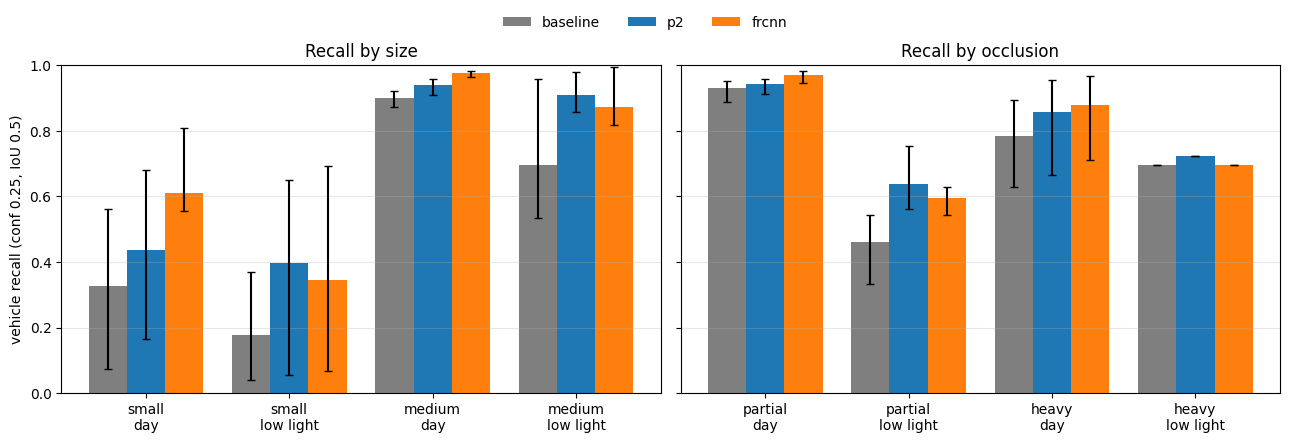

Saved /content/drive/MyDrive/DATA255/outputs/comparison/recall_day_vs_low_light.png


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
panels = [('size', ['small', 'medium'], axes[0]), ('occlusion', ['partial_occlusion', 'heavy_occlusion'], axes[1])]
colors = {'baseline': '#7f7f7f', 'p2': '#1f77b4', 'frcnn': '#ff7f0e'}
for title, subs, ax in panels:
    groups = [(s, c) for s in subs for c in ['day', 'low_light']]
    width = 0.8 / len(MODELS)
    for k, m in enumerate(MODELS):
        r = [eb.loc[('recall', s, c, m)] for s, c in groups]
        x = np.arange(len(groups)) + (k - (len(MODELS) - 1) / 2) * width
        ax.bar(x, [v['value'] for v in r], width, color=colors.get(m), label=m,
               yerr=[[v['value'] - v['ci_low'] for v in r], [v['ci_high'] - v['value'] for v in r]], capsize=3)
    ax.set_xticks(np.arange(len(groups)))
    ax.set_xticklabels([f"{s.replace('_occlusion', '').replace('_', ' ')}\n{c.replace('_', ' ')}" for s, c in groups])
    ax.set_title(f'Recall by {title}'); ax.set_ylim(0, 1); ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('vehicle recall (conf 0.25, IoU 0.5)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=len(MODELS), frameon=False, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'recall_day_vs_low_light.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved', OUTPUT_DIR / 'recall_day_vs_low_light.png')

## 8. COUNTING WITH A VAL TUNED THRESHOLD

Choose each detector's counting threshold on val, then evaluate it on test.

Counting threshold chosen on val: {'baseline': 0.2, 'p2': 0.2, 'frcnn': 0.45}


,condition,system,threshold (val),count_MAE @0.25,count_MAE tuned,ci_low,ci_high,count_error_pct tuned,diff_vs_baseline,diff_ci_low,diff_ci_high,clear
0,all,baseline,0.20,0.951,0.963,0.758,1.127,18.138,NaN,NaN,NaN,NaN
1,all,p2,0.20,0.754,0.832,0.589,1.054,15.664,-0.131,-0.255,0.013,False
2,all,frcnn,0.45,1.616,0.910,0.681,1.162,17.139,-0.053,-0.302,0.239,False
3,day,baseline,0.20,0.816,0.862,0.611,1.066,15.312,NaN,NaN,NaN,NaN
4,day,p2,0.20,0.714,0.790,0.473,1.066,14.039,-0.072,-0.218,0.099,False
5,day,frcnn,0.45,1.663,0.894,0.608,1.207,15.881,0.032,-0.276,0.399,False
6,low_light,baseline,0.20,1.461,1.347,1.123,1.473,32.727,NaN,NaN,NaN,NaN
7,low_light,p2,0.20,0.904,0.990,0.579,1.161,24.056,-0.357,-0.544,-0.141,True
8,low_light,frcnn,0.45,1.440,0.973,0.816,1.181,23.636,-0.374,-0.550,-0.121,True


Updated final_table.csv / .md with the tuned-threshold counting columns


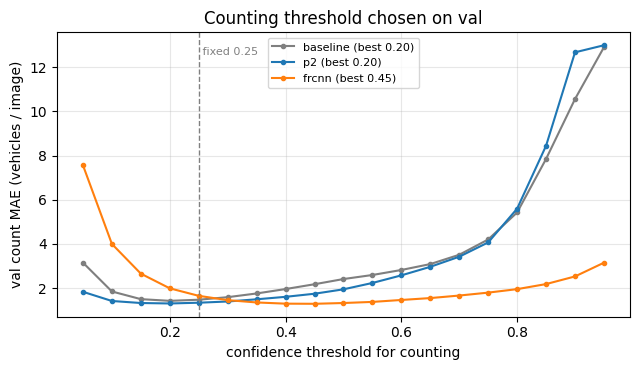

In [27]:
VAL_FILES = {'baseline': BASELINE_DIR / 'yolo_detections_val.csv', 'p2': P2_DIR / 'p2_detections_val.csv',
             'frcnn': FRCNN_DIR / 'frcnn_detections_val.csv'}
VAL_GT_FILE = BASELINE_DIR / 'ground_truth_val.csv'
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.05), 2)
tuned_systems = [m for m in MODELS if VAL_FILES.get(m, Path('-')).exists()]
for m in MODELS:
    if m not in tuned_systems:
        print(f'{m}: no val detections file, skipped')
assert VAL_GT_FILE.exists() and tuned_systems, 'needs ground_truth_val.csv and at least one val detections file'

val_df = manifest[manifest['split'] == 'val'].reset_index(drop=True)
val_gt = pd.read_csv(VAL_GT_FILE)[['image', 'class_id'] + BOX_COLS]


def per_image_abs_err(gt, det, images_df, conf):
    # |predicted - true| vehicles per image (all classes together), counting boxes with confidence >= conf
    g = gt.groupby('image').size().reindex(images_df['image'], fill_value=0).to_numpy()
    p = det[det['confidence'] >= conf].groupby('image').size().reindex(images_df['image'], fill_value=0).to_numpy()
    return np.abs(p - g), g


curve, best_thr = [], {}
for m in tuned_systems:
    vdet = pd.read_csv(VAL_FILES[m])[['image', 'class_id', 'confidence'] + BOX_COLS]
    for t in THRESHOLDS:
        curve.append({'system': m, 'threshold': t, 'val_count_MAE': per_image_abs_err(val_gt, vdet, val_df, t)[0].mean()})
curve = pd.DataFrame(curve)
for m, g in curve.groupby('system', sort=False):
    best_thr[m] = float(g.loc[g['val_count_MAE'].idxmin(), 'threshold'])
curve.to_csv(OUTPUT_DIR / 'count_threshold_curve_val.csv', index=False)

# test, once, at each detector's val-chosen threshold; error bars by resampling test videos (same W as section 5)
gt_total = test_gt.groupby('image').size().reindex(test_df['image'], fill_value=0).to_numpy()
seq_of = test_df['sequence'].to_numpy()
err_video, gt_video = {}, pd.Series(gt_total).groupby(seq_of).sum().reindex(V).to_numpy(float)
for m in tuned_systems:
    e, _ = per_image_abs_err(test_gt, dets[m], test_df, best_thr[m])
    err_video[m] = pd.Series(e).groupby(seq_of).sum().reindex(V).to_numpy(float)


def mae(weights, m, cond):
    w = weights * np.isin(videos.to_numpy(), CONDS[cond]).astype(float)
    return (w @ err_video[m]) / (w @ n_img)


rows = []
for cond in CONDS:
    for m in tuned_systems:
        b = mae(W, m, cond)
        lo, hi = np.nanpercentile(b, [2.5, 97.5])
        w1 = W1 * np.isin(videos.to_numpy(), CONDS[cond]).astype(float)
        row = {'condition': cond, 'system': m, 'threshold (val)': best_thr[m],
               'count_MAE @0.25': float(error_bars.set_index(['metric', 'subset', 'condition', 'system'])
                                        .loc[('count_MAE', 'all', cond, m), 'value']),
               'count_MAE tuned': mae(W1, m, cond)[0], 'ci_low': lo, 'ci_high': hi,
               'count_error_pct tuned': 100 * (w1 @ err_video[m])[0] / (w1 @ gt_video)[0]}
        if m != 'baseline' and 'baseline' in tuned_systems:
            d = b - mae(W, 'baseline', cond)
            row['diff_vs_baseline'] = row['count_MAE tuned'] - mae(W1, 'baseline', cond)[0]
            row['diff_ci_low'], row['diff_ci_high'] = np.nanpercentile(d, [2.5, 97.5])
            row['clear'] = bool(row['diff_ci_low'] > 0 or row['diff_ci_high'] < 0)
        rows.append(row)
count_tuned = pd.DataFrame(rows)
count_tuned.to_csv(OUTPUT_DIR / 'count_tuned_threshold.csv', index=False)
print('Counting threshold chosen on val:', best_thr)
display(count_tuned.round(3))

# add to the final table
ct = count_tuned.set_index(['condition', 'system'])
final_table['count threshold (val)'] = final_table['system'].map(best_thr)
for cond, label in [('all', 'count MAE, tuned threshold'), ('low_light', 'count MAE, tuned, low light')]:
    final_table[label] = [f"{ct.loc[(cond, m), 'count_MAE tuned']:.3f} [{ct.loc[(cond, m), 'ci_low']:.3f}, {ct.loc[(cond, m), 'ci_high']:.3f}]"
                          if (cond, m) in ct.index else '' for m in final_table['system']]
final_table.to_csv(OUTPUT_DIR / 'final_table.csv', index=False)
try:
    (OUTPUT_DIR / 'final_table.md').write_text(final_table.round(3).to_markdown(index=False))
except ImportError:
    (OUTPUT_DIR / 'final_table.md').write_text(final_table.round(3).to_string(index=False))
print('Updated final_table.csv / .md with the tuned-threshold counting columns')

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for m, g in curve.groupby('system', sort=False):
    ax.plot(g['threshold'], g['val_count_MAE'], marker='o', ms=3, color=colors.get(m), label=f'{m} (best {best_thr[m]:.2f})')
ax.axvline(COUNT_CONF, color='grey', ls='--', lw=1)
ax.text(COUNT_CONF, ax.get_ylim()[1] * 0.95, ' fixed 0.25', fontsize=8, color='grey', va='top')
ax.set_xlabel('confidence threshold for counting'); ax.set_ylabel('val count MAE (vehicles / image)')
ax.set_title('Counting threshold chosen on val'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'count_threshold_val.png', dpi=150, bbox_inches='tight')
plt.show()